## Prediction and analysis of socioeconomic factors influencing crime in the United Kingdom using Machine Learning techniques

Crime is one of the most relevant and complex social phenomena in contemporary societies. In the United Kingdom, crime levels have shown significant variations across regions and districts, suggesting a strong influence of socioeconomic factors such as poverty, unemployment, education, and population density. Analysing these relationships not only contributes to a deeper understanding of criminal patterns but also provides an empirical foundation for the design of public policies aimed at prevention and public safety.

In recent years, the use of Machine Learning (ML) has made it possible to model social phenomena with greater precision and explanatory power than traditional statistical approaches. These techniques facilitate the identification of non-linear relationships between variables and the detection of hidden patterns within large volumes of data. In the context of criminality, ML models can predict crime levels based on multiple demographic and socioeconomic variables, thereby contributing to a more informed management of security resources.

This study proposes the development of a machine learning model capable of predicting crime levels by geographical area in the United Kingdom, using open data from the UK Police Data API, the Office for National Statistics (ONS), and the Index of Multiple Deprivation (IMD). In addition to building the predictive model, an interpretative analysis of the most influential variables is carried out in order to identify the factors that contribute most to the increase or reduction of criminality.

### PREPARACION DE ENTORNO Y OPTIMIZACION 

In [6]:
pip install -U numpy scipy pandas scikit-learn numexpr bottleneck

Note: you may need to restart the kernel to use updated packages.


In [7]:
import numpy
numpy.__config__.show()


Build Dependencies:
  blas:
    detection method: pkgconfig
    found: true
    include directory: /opt/_internal/cpython-3.12.12/lib/python3.12/site-packages/scipy_openblas64/include
    lib directory: /opt/_internal/cpython-3.12.12/lib/python3.12/site-packages/scipy_openblas64/lib
    name: scipy-openblas
    openblas configuration: OpenBLAS 0.3.30  USE64BITINT DYNAMIC_ARCH NO_AFFINITY
      Haswell MAX_THREADS=64
    pc file directory: /project/.openblas
    version: 0.3.30
  lapack:
    detection method: pkgconfig
    found: true
    include directory: /opt/_internal/cpython-3.12.12/lib/python3.12/site-packages/scipy_openblas64/include
    lib directory: /opt/_internal/cpython-3.12.12/lib/python3.12/site-packages/scipy_openblas64/lib
    name: scipy-openblas
    openblas configuration: OpenBLAS 0.3.30  USE64BITINT DYNAMIC_ARCH NO_AFFINITY
      Haswell MAX_THREADS=64
    pc file directory: /project/.openblas
    version: 0.3.30
Compilers:
  c:
    commands: cc
    linker: ld.bfd
  

In [8]:
export OMP_NUM_THREADS=24
export MKL_NUM_THREADS=24
export NUMEXPR_MAX_THREADS=24

SyntaxError: invalid syntax (420121348.py, line 1)

### Codigo para hacer un merge de todos los csvs de police.uk (ayuda y generaci´on de codigo de chatgpt)


In [ ]:
!pip install pandas tqdm
!pip install pandas tqdm


In [ ]:
#!/usr/bin/env python3
import os
import glob
import pandas as pd
from tqdm import tqdm

# Directorio base (ajústalo si lo necesitas)
BASE_DIR = "/home/clientefinal/SERVIDOR/Jupyter/ARCHIVOS"

# CSV final
OUTPUT_FILE = "uk_crime_merged_2025.csv"

# Buscar todos los CSV dentro de subcarpetas (recursivamente)
all_csvs = glob.glob(os.path.join(BASE_DIR, "*/*.csv"))

print(f"Archivos encontrados: {len(all_csvs)}")

dfs = []
for csv_path in tqdm(all_csvs, desc="Leyendo y uniendo CSVs"):
    try:
        df = pd.read_csv(csv_path)
        df["source_file"] = os.path.basename(csv_path)  # opcional: saber de qué mes viene
        dfs.append(df)
    except Exception as e:
        print(f" Error leyendo {csv_path}: {e}")

# Unir todos
merged = pd.concat(dfs, ignore_index=True)

# Eliminar duplicados (si existen)
if "Crime ID" in merged.columns:
    merged.drop_duplicates(subset=["Crime ID"], inplace=True)

# Guardar
merged.to_csv(OUTPUT_FILE, index=False)
print(f"CSV final guardado: {OUTPUT_FILE}")
print(f"Filas totales: {len(merged):,}")


Archivos encontrados: 4515


Leyendo y uniendo CSVs:  38%|███▊      | 1712/4515 [00:43<01:10, 39.51it/s]


KeyboardInterrupt: 

In [ ]:
import pandas as pd

df = pd.read_csv("/home/clientefinal/SERVIDOR/Jupyter/uk_crime_merged_2025.csv", low_memory=False)
print(df.info())
print(df.describe())
print(df.isna().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14801008 entries, 0 to 14801007
Data columns (total 27 columns):
 #   Column                                    Dtype  
---  ------                                    -----  
 0   Crime ID                                  object 
 1   Month                                     object 
 2   Reported by                               object 
 3   Falls within                              object 
 4   Longitude                                 float64
 5   Latitude                                  float64
 6   Location                                  object 
 7   LSOA code                                 object 
 8   LSOA name                                 object 
 9   Crime type                                object 
 10  Last outcome category                     object 
 11  Context                                   float64
 12  source_file                               object 
 13  Outcome type                              object 
 14  

# Despues del analisis hemos visto que ha que quitar ciertos casos 

vienen del dataset de Stop and Search, pero no están presentes en tus CSV de crimen (solo en algunos casos).

Lo que está bien

Tienes coordenadas (Longitude, Latitude) — aunque faltan unos ~275k.

Month, LSOA code, Crime type, Last outcome category están presentes.

source_file te dice la procedencia (por mes, útil para orden temporal).

### LImpieza 

In [ ]:
import pandas as pd

df = pd.read_csv("/home/clientefinal/SERVIDOR/Jupyter/uk_crime_merged_2025.csv", low_memory=False)

# eliminar columnas totalmente vacías
df = df.dropna(axis=1, how='all')

# columnas a conservar manualmente
keep = [
    "Crime ID", "Month", "Longitude", "Latitude",
    "LSOA code", "LSOA name", "Crime type", "Last outcome category"
]
df = df[keep]

# eliminar filas sin coordenadas o sin código LSOA
df = df.dropna(subset=["Longitude", "Latitude", "LSOA code"])

# asegurarte de que 'Month' es fecha
df["Month"] = pd.to_datetime(df["Month"], errors="coerce")

df.info()
print(df["Crime type"].value_counts().head())


KeyboardInterrupt: 

## Agrupar por LSOA y mes

In [ ]:
import pandas as pd

df = pd.read_csv("/home/clientefinal/SERVIDOR/Jupyter/uk_crime_merged_2025.csv", parse_dates=["Month"])

crime_agg = (
    df.groupby(["Month", "LSOA code", "LSOA name"])
      .size()
      .reset_index(name="crime_count")
)

crime_agg.to_csv("crime_aggregated.csv", index=False)
print(crime_agg.head())


/tmp/ipykernel_578433/3300293342.py:3: DtypeWarning: Columns (9,10,13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/home/clientefinal/SERVIDOR/Jupyter/uk_crime_merged_2025.csv", parse_dates=["Month"])


       Month  LSOA code                  LSOA name  crime_count
0 2022-09-01  E01000001        City of London 001A           13
1 2022-09-01  E01000002        City of London 001B           27
2 2022-09-01  E01000003        City of London 001C            6
3 2022-09-01  E01000005        City of London 001E           62
4 2022-09-01  E01000006  Barking and Dagenham 016A            7


In [ ]:
import pandas as pd
import os
import re

base = "/home/clientefinal/SERVIDOR/Jupyter/census2021"

datasets = {
    "ts001_population": "census2021-ts001/census2021-ts001-lsoa.csv",
    "ts004_birth_country": "census2021-ts004/census2021-ts004-lsoa.csv",
    "ts006_density": "census2021-ts006/census2021-ts006-lsoa.csv",
    "ts011_deprivation": "census2021-ts011/census2021-ts011-lsoa.csv",
    "ts038_disability": "census2021-ts038/census2021-ts038-lsoa.csv",
    "ts063_occupation": "census2021-ts063/census2021-ts063-lsoa.csv",
    "ts065_unemployment_history": "census2021-ts065/census2021-ts065-lsoa.csv",
    "ts066_economic": "census2021-ts066/census2021-ts066-lsoa.csv",
    "ts067_education": "census2021-ts067/census2021-ts067-lsoa.csv",
}

def load_clean(path):
    """Lee CSV y selecciona columnas representativas automáticamente"""
    df = pd.read_csv(path, dtype=str, low_memory=False)
    first_col = df.columns[0]
    df = df.rename(columns={first_col: "LSOA_code"})
    df["LSOA_code"] = df["LSOA_code"].astype(str).str.strip()

    # Mantén LSOA y columnas que parezcan totales o sumarios
    keep_cols = ["LSOA_code"]
    for c in df.columns:
        if re.search(r"(?i)(total|all|overall|density|count|population)", c):
            keep_cols.append(c)
        elif c.endswith("0001") or c.endswith("001"):
            keep_cols.append(c)

    df = df[keep_cols].drop_duplicates(subset=["LSOA_code"])
    return df

merged = None

for name, rel_path in datasets.items():
    path = os.path.join(base, rel_path)
    print(f"📂 Loading {name} ...")
    df = load_clean(path)
    print(f"   → {df.shape[0]} rows, {df.shape[1]} cols: {list(df.columns)[:5]}...")

    if merged is None:
        merged = df
    else:
        merged = merged.merge(df, on="LSOA_code", how="left")

    print(f"✅ Merged shape: {merged.shape}")

out_path = f"{base}/census_features_full.csv"
merged.to_csv(out_path, index=False)
print(f"\n💾 Done! Saved to: {out_path}")


📂 Loading ts001_population ...
   → 1 rows, 2 cols: ['LSOA_code', 'Residence type: Total; measures: Value']...
✅ Merged shape: (1, 2)
📂 Loading ts004_birth_country ...
   → 1 rows, 16 cols: ['LSOA_code', 'Country of birth: Total; measures: Value', 'Country of birth: Europe; measures: Value', 'Country of birth: Europe: United Kingdom; measures: Value', 'Country of birth: Europe: EU countries; measures: Value']...
✅ Merged shape: (1, 17)
📂 Loading ts006_density ...
   → 1 rows, 2 cols: ['LSOA_code', 'Population Density: Persons per square kilometre; measures: Value']...
✅ Merged shape: (1, 18)
📂 Loading ts011_deprivation ...
   → 1 rows, 2 cols: ['LSOA_code', 'Household deprivation: Total: All households; measures: Value']...
✅ Merged shape: (1, 19)
📂 Loading ts038_disability ...
   → 1 rows, 2 cols: ['LSOA_code', 'Disability: Total: All usual residents']...
✅ Merged shape: (1, 20)
📂 Loading ts063_occupation ...
   → 1 rows, 2 cols: ['LSOA_code', 'Occupation (current): Total: All usual r

UNIFICACION DE DATASET DE FACTORES SOCIOECONOMICOS 

In [ ]:
import pandas as pd
import os

base = "/home/clientefinal/SERVIDOR/Jupyter/census2021"

datasets = {
    "ts001_population": "census2021-ts001/census2021-ts001-lsoa.csv",
    "ts004_birth_country": "census2021-ts004/census2021-ts004-lsoa.csv",
    "ts006_density": "census2021-ts006/census2021-ts006-lsoa.csv",
    "ts011_deprivation": "census2021-ts011/census2021-ts011-lsoa.csv",
    "ts038_disability": "census2021-ts038/census2021-ts038-lsoa.csv",
    "ts063_occupation": "census2021-ts063/census2021-ts063-lsoa.csv",
    "ts065_unemployment_history": "census2021-ts065/census2021-ts065-lsoa.csv",
    "ts066_economic": "census2021-ts066/census2021-ts066-lsoa.csv",
    "ts067_education": "census2021-ts067/census2021-ts067-lsoa.csv",
}

def load_clean(path):
    """Lee solo columnas necesarias y limpia IDs"""
    df = pd.read_csv(path, dtype=str, low_memory=False)
    first_col = df.columns[0]
    df = df.rename(columns={first_col: "LSOA_code"})
    df["LSOA_code"] = df["LSOA_code"].astype(str).str.strip()
    keep_cols = [c for c in df.columns if c == "LSOA_code" or c.endswith("0001")]
    return df[keep_cols].drop_duplicates(subset=["LSOA_code"])

merged = None

for name, rel_path in datasets.items():
    path = os.path.join(base, rel_path)
    print(f"📂 Loading {name} ...")

    df = load_clean(path)
    print(f"   → {df.shape[0]} rows, {df.shape[1]} cols")

    if merged is None:
        merged = df
    else:
        # Unión progresiva segura
        merged = merged.merge(df, on="LSOA_code", how="left", validate="1:1")

    print(f"✅ Merged shape: {merged.shape}")

out_path = f"{base}/census_features_full.csv"
merged.to_csv(out_path, index=False)
print(f"\n💾 Done! Saved to: {out_path}")



📂 Loading ts001_population ...
   → 1 rows, 1 cols
✅ Merged shape: (1, 1)
📂 Loading ts004_birth_country ...
   → 1 rows, 1 cols
✅ Merged shape: (1, 1)
📂 Loading ts006_density ...
   → 1 rows, 1 cols
✅ Merged shape: (1, 1)
📂 Loading ts011_deprivation ...
   → 1 rows, 1 cols
✅ Merged shape: (1, 1)
📂 Loading ts038_disability ...
   → 1 rows, 1 cols
✅ Merged shape: (1, 1)
📂 Loading ts063_occupation ...
   → 1 rows, 1 cols
✅ Merged shape: (1, 1)
📂 Loading ts065_unemployment_history ...
   → 1 rows, 1 cols
✅ Merged shape: (1, 1)
📂 Loading ts066_economic ...
   → 1 rows, 1 cols
✅ Merged shape: (1, 1)
📂 Loading ts067_education ...
   → 1 rows, 1 cols
✅ Merged shape: (1, 1)

💾 Done! Saved to: /home/clientefinal/SERVIDOR/Jupyter/census2021/census_features_full.csv


In [ ]:
import os
os.cpu_count()


48

In [ ]:

#!/usr/bin/env python3
# ===============================================
# UK Census 2021 (LSOA) → Parquet unificado
# Autor: [Tu nombre]
# Descripción:
#   Fusiona todos los archivos -lsoa.csv del Censo 2021
#   en un único archivo Parquet optimizado por LSOA.
# ===============================================

import os
import re
import sys
from glob import glob

import ray
import modin.pandas as pd

# -----------------------------------------------
# Configuración inicial
# -----------------------------------------------
BASE_DIR = os.path.expanduser("~/SERVIDOR/Jupyter/census2021")
OUTPUT_PATH = os.path.join(BASE_DIR, "census_features_full.parquet")

# Iniciar Ray para paralelismo
if not ray.is_initialized():
    ray.init(num_cpus=24, ignore_reinit_error=True)
    print(f"✅ Ray inicializado con {ray.cluster_resources()['CPU']} CPUs\n")

# -----------------------------------------------
# Detección automática de archivos
# -----------------------------------------------
lsoa_files = sorted(glob(os.path.join(BASE_DIR, "census2021-ts*/census2021-ts*-lsoa.csv")))

if not lsoa_files:
    sys.exit("❌ No se encontraron archivos '-lsoa.csv'. Revisa la ruta BASE_DIR o nombres de archivo.")

print(f"📂 Archivos detectados ({len(lsoa_files)}):")
for f in lsoa_files:
    print("  -", os.path.basename(f))
print("-" * 60)

# -----------------------------------------------
# Fusión progresiva
# -----------------------------------------------
merged_df = None

for path in lsoa_files:
    dataset_code = re.search(r"(census2021-ts\d+)", path).group(1)
    print(f"\n📊 Procesando {dataset_code}...")

    try:
        df = pd.read_csv(path, low_memory=False)
    except Exception as e:
        print(f"⚠️ Error leyendo {path}: {e}")
        continue

    # Normalizar nombre de columna LSOA
    lsoa_col_candidates = [c for c in df.columns if "LSOA" in c.upper() or "geography code" in c.lower()]
    if not lsoa_col_candidates:
        print(f"⚠️ No se encontró columna LSOA en {path}. Saltando...")
        continue
    lsoa_col = lsoa_col_candidates[0]
    df.rename(columns={lsoa_col: "LSOA code"}, inplace=True)

    # Eliminar columnas textuales o no numéricas irrelevantes
    drop_cols = [c for c in df.columns if re.search(r"name|Area|Geography", c, re.IGNORECASE)]
    df.drop(columns=drop_cols, inplace=True, errors="ignore")

    # Renombrar columnas para evitar colisiones
    value_cols = [c for c in df.columns if c != "LSOA code"]
    df.rename(columns={c: f"{dataset_code}_{c}" for c in value_cols}, inplace=True)

    # Mostrar resumen
    print(f"   ➕ Columnas agregadas: {len(value_cols)} | Filas: {len(df):,}")

    # Merge progresivo
    if merged_df is None:
        merged_df = df
    else:
        merged_df = merged_df.merge(df, on="LSOA code", how="outer")

print("\n✅ Todos los datasets combinados correctamente.")
print(f"📈 Total de filas: {len(merged_df):,}")
print(f"📊 Total de columnas: {len(merged_df.columns):,}")

# -----------------------------------------------
# Guardar resultado
# -----------------------------------------------
os.makedirs(os.path.dirname(OUTPUT_PATH), exist_ok=True)
merged_df.to_parquet(OUTPUT_PATH, index=False)
print(f"\n💾 Archivo final guardado en:\n{OUTPUT_PATH}")

# -----------------------------------------------
# Export opcional de preview
# -----------------------------------------------
preview_csv = OUTPUT_PATH.replace(".parquet", "_preview.csv")
merged_df.head(1000).to_csv(preview_csv, index=False)
print(f"📄 Muestra de 1.000 filas exportada a:\n{preview_csv}")

print("\n🚀 Conversión y fusión completadas con éxito.")


📂 Archivos detectados (5):
  - census2021-ts001-lsoa.csv
  - census2021-ts006-lsoa.csv
  - census2021-ts011-lsoa.csv
  - census2021-ts066-lsoa.csv
  - census2021-ts067-lsoa.csv
------------------------------------------------------------

📊 Procesando census2021-ts001...
   ➕ Columnas agregadas: 4 | Filas: 35,672

📊 Procesando census2021-ts006...
   ➕ Columnas agregadas: 2 | Filas: 35,672


Please refer to https://modin.readthedocs.io/en/stable/supported_apis/defaulting_to_pandas.html for explanation.



📊 Procesando census2021-ts011...
   ➕ Columnas agregadas: 7 | Filas: 35,672



📊 Procesando census2021-ts066...
   ➕ Columnas agregadas: 32 | Filas: 35,672



📊 Procesando census2021-ts067...
   ➕ Columnas agregadas: 9 | Filas: 35,672



✅ Todos los datasets combinados correctamente.
📈 Total de filas: 35,672
📊 Total de columnas: 55

💾 Archivo final guardado en:
/home/clientefinal/SERVIDOR/Jupyter/census2021/census_features_full.parquet
📄 Muestra de 1.000 filas exportada a:
/home/clientefinal/SERVIDOR/Jupyter/census2021/census_features_full_preview.csv

🚀 Conversión y fusión completadas con éxito.


In [ ]:
import modin.pandas as pd
df = pd.read_parquet("~/SERVIDOR/Jupyter/census2021/census_features_full.parquet")
print(df["LSOA code"].nunique())


35672


## FINAL MERGE 

In [ ]:
#!/usr/bin/env python3
# ===============================================================
# COMBINACIÓN FINAL: UK Crime (2022–2025) + Census 2021 (LSOA)
# Adaptado al entorno real del servidor (~/SERVIDOR/Jupyter)
# ===============================================================

import os
import re
import numpy as np
import modin.pandas as pd
import ray

# ---------------------------------------------------
# CONFIGURACIÓN DE ENTORNO
# ---------------------------------------------------
BASE_DIR = os.path.expanduser("~/SERVIDOR/Jupyter")
CENSUS_PATH = os.path.join(BASE_DIR, "census2021", "census_features_full.parquet")

# Dataset de crimen (usa el consolidado final)
CRIME_PATH = os.path.join(BASE_DIR, "crime_aggregated.csv")
if not os.path.exists(CRIME_PATH):
    CRIME_PATH = os.path.join(BASE_DIR, "uk_crime_merged_2025.csv")

OUTPUT_PATH = os.path.join(BASE_DIR, "dataset_ml.parquet")

# Inicializar Ray para paralelismo
if not ray.is_initialized():
    ray.init(num_cpus=24, ignore_reinit_error=True)
    print(f"✅ Ray inicializado con {ray.cluster_resources()['CPU']} CPUs\n")

# ---------------------------------------------------
# 1️⃣ CARGA DE DATASETS
# ---------------------------------------------------
print("📂 Cargando datasets...")
crime_df = pd.read_csv(CRIME_PATH, low_memory=False)
census_df = pd.read_parquet(CENSUS_PATH)

print(f"Crimen: {len(crime_df):,} filas | {len(crime_df.columns)} columnas")
print(f"Censo:  {len(census_df):,} filas | {len(census_df.columns)} columnas")

# ---------------------------------------------------
# 2️⃣ LIMPIEZA Y NORMALIZACIÓN DE COLUMNAS
# ---------------------------------------------------
# Normalizar LSOA
for df in [crime_df, census_df]:
    rename_candidates = [c for c in df.columns if "LSOA" in c.upper()]
    if rename_candidates:
        df.rename(columns={rename_candidates[0]: "LSOA code"}, inplace=True)

# Mantener solo columnas necesarias del crimen
cols_keep = ["Month", "LSOA code", "Crime type", "Last outcome category", "crime_count"]
crime_df = crime_df[[c for c in cols_keep if c in crime_df.columns]]

# Eliminar nulos y duplicados
crime_df = crime_df.dropna(subset=["LSOA code"])
crime_df = crime_df.drop_duplicates(subset=["Month", "LSOA code"])

# ---------------------------------------------------
# 3️⃣ MERGE CRIMEN + CENSO
# ---------------------------------------------------
print("\n🔗 Fusionando datasets (LEFT JOIN por LSOA code)...")
dataset = crime_df.merge(census_df, on="LSOA code", how="left")
print(f"✅ Merge completado: {len(dataset):,} filas | {len(dataset.columns)} columnas")

# ---------------------------------------------------
# 4️⃣ FEATURE ENGINEERING
# ---------------------------------------------------
print("\n🧮 Generando variables temporales y derivadas...")

# Fecha y componentes temporales
dataset["Month"] = pd.to_datetime(dataset["Month"], errors="coerce")
dataset["year"] = dataset["Month"].dt.year
dataset["month_num"] = dataset["Month"].dt.month
dataset["quarter"] = dataset["Month"].dt.quarter
dataset["season"] = dataset["Month"].dt.month % 12 // 3 + 1  # 1=winter, 2=spring, 3=summer, 4=autumn

# --- crime_rate ---
pop_cols = [c for c in dataset.columns if re.search("resident|population", c, re.IGNORECASE)]
if pop_cols:
    dataset["crime_rate"] = dataset["crime_count"] / dataset[pop_cols[0]]
else:
    dataset["crime_rate"] = np.nan
    print("⚠️ No se encontró columna de población; se omitió 'crime_rate'.")

# --- Lag mensual ---
dataset = dataset.sort_values(["LSOA code", "Month"])
dataset["crime_count_prev"] = dataset.groupby("LSOA code")["crime_count"].shift(1)
dataset["crime_change_pct"] = (
    (dataset["crime_count"] - dataset["crime_count_prev"]) / dataset["crime_count_prev"]
).replace([np.inf, -np.inf], np.nan)

dataset["crime_count_prev"].fillna(0, inplace=True)
dataset["crime_change_pct"].fillna(0, inplace=True)

# ---------------------------------------------------
# 5️⃣ LIMPIEZA FINAL
# ---------------------------------------------------
dataset = dataset.drop_duplicates(subset=["Month", "LSOA code"]).reset_index(drop=True)
dataset = dataset.sort_values(["LSOA code", "Month"])
print(f"🧹 Dataset limpio: {len(dataset):,} filas | {len(dataset.columns)} columnas")

# ---------------------------------------------------
# 6️⃣ GUARDAR RESULTADOS
# ---------------------------------------------------
dataset.to_parquet(OUTPUT_PATH, index=False)
print(f"\n💾 Dataset final guardado en:\n{OUTPUT_PATH}")

preview_csv = OUTPUT_PATH.replace(".parquet", "_preview.csv")
dataset.head(1000).to_csv(preview_csv, index=False)
print(f"📄 Vista previa exportada a:\n{preview_csv}")

print("\n🚀 Dataset final listo para modelado ML.")


📂 Cargando datasets...
Crimen: 1,192,676 filas | 4 columnas
Censo:  35,672 filas | 55 columnas

🔗 Fusionando datasets (LEFT JOIN por LSOA code)...
✅ Merge completado: 1,186,438 filas | 57 columnas

🧮 Generando variables temporales y derivadas...
🧹 Dataset limpio: 1,186,438 filas | 64 columnas

💾 Dataset final guardado en:
/home/clientefinal/SERVIDOR/Jupyter/dataset_ml.parquet
📄 Vista previa exportada a:
/home/clientefinal/SERVIDOR/Jupyter/dataset_ml_preview.csv

🚀 Dataset final listo para modelado ML.


### Comprobacion formato

In [ ]:
#!/usr/bin/env python3
# ===============================================
# Verificación y exploración del dataset_ml.parquet
# ===============================================

import os
import modin.pandas as pd
import ray
import numpy as np

# Inicializar Ray
if not ray.is_initialized():
    ray.init(num_cpus=24, ignore_reinit_error=True)

# Rutas
BASE_DIR = os.path.expanduser("~/SERVIDOR/Jupyter")
DATASET_PATH = os.path.join(BASE_DIR, "dataset_ml.parquet")

# ===============================================
# 1️⃣ Cargar dataset final
# ===============================================
print("📂 Cargando dataset final...")
df = pd.read_parquet(DATASET_PATH)
print(f"✅ Filas: {len(df):,} | Columnas: {len(df.columns)}")

# ===============================================
# 2️⃣ Revisión general de estructura
# ===============================================
print("\n📋 Primeras filas:")
print(df.head(5))

print("\n📊 Columnas principales:")
print(df.columns[:20])  # muestra primeras 20

print("\n🔢 Tipos de datos:")
print(df.dtypes.head(15))

# ===============================================
# 3️⃣ Validación de fechas
# ===============================================
if "Month" in df.columns:
    df["Month"] = pd.to_datetime(df["Month"], errors="coerce")
    print("\n🗓️ Rango temporal:")
    print("Desde:", df["Month"].min())
    print("Hasta:", df["Month"].max())
else:
    print("⚠️ No se encontró columna 'Month'.")

# ===============================================
# 4️⃣ Validación de LSOA
# ===============================================
if "LSOA code" in df.columns:
    n_unique = df["LSOA code"].nunique()
    print(f"\n🏙️ Zonas únicas (LSOA): {n_unique:,}")
else:
    print("⚠️ No se encontró columna 'LSOA code'.")

# ===============================================
# 5️⃣ Chequeo de nulls y duplicados
# ===============================================
print("\n🔍 Valores nulos por columna (top 15):")
print(df.isna().sum().sort_values(ascending=False).head(15))

duplicados = df.duplicated(subset=["Month", "LSOA code"]).sum()
print(f"\n🧹 Registros duplicados (Month+LSOA): {duplicados:,}")

# ===============================================
# 6️⃣ Validación de features derivadas
# ===============================================
features_check = ["crime_count", "crime_rate", "crime_count_prev", "crime_change_pct"]
print("\n🧩 Estadísticas básicas de variables clave:")
print(df[features_check].describe().T)

# ===============================================
# 7️⃣ Sanity checks adicionales
# ===============================================
print("\n📈 Número medio de crímenes por mes (primeras 10 fechas):")
print(df.groupby("Month")["crime_count"].mean().head(10))

print("\n📉 Ejemplo: evolución del crimen en un LSOA aleatorio:")
sample_lsoa = df["LSOA code"].dropna().sample(1).iloc[0]
print("Ejemplo LSOA:", sample_lsoa)
print(df[df["LSOA code"] == sample_lsoa][["Month", "crime_count", "crime_rate"]].head(10))

print("\n✅ Verificación completada.")


📂 Cargando dataset final...
✅ Filas: 1,186,438 | Columnas: 64

📋 Primeras filas:
       Month  LSOA code  crime_count  census2021-ts001_date  \
0 2022-09-01  E01000001           13                 2021.0   
1 2022-10-01  E01000001           14                 2021.0   
2 2022-11-01  E01000001            9                 2021.0   
3 2022-12-01  E01000001           19                 2021.0   
4 2023-01-01  E01000001            6                 2021.0   

   census2021-ts001_Residence type: Total; measures: Value  \
0                                             1475.0         
1                                             1475.0         
2                                             1475.0         
3                                             1475.0         
4                                             1475.0         

   census2021-ts001_Residence type: Lives in a household; measures: Value  \
0                                             1475.0                        
1            

SPLIT DE DATOS 

V. R. Joseph (2022). Optimal Ratio for Data Splitting. Statistical Analysis and Data Mining 15(4): 531–538.
Resultado clave: el ratio óptimo train:test es (...)...
https://arxiv.org/abs/2202.03326?

In [2]:
import numpy as np, pandas as pd

df = pd.read_parquet("~/SERVIDOR/Jupyter/dataset_ml.parquet")
features = [c for c in df.columns if c not in {"Month","LSOA code","crime_count"} and np.issubdtype(df[c].dtype, np.number)]
k = len(features)          # nº de predictores
p = k + 1                  # + intercepto
train_prop = np.sqrt(p)/(np.sqrt(p)+1)
test_prop  = 1/(np.sqrt(p)+1)
train_prop, test_prop, p, k


(np.float64(0.8873113463276753), np.float64(0.11268865367232477), 62, 61)

In [1]:
# ===============================================================
# MODELADO ML - SPLIT ÓPTIMO SEGÚN JOSEPH (2022)
# ---------------------------------------------------------------
# Train ≈ 79.9 % | Val ≈ 8.9 % | Test ≈ 11.2 %
# Dataset: ~/SERVIDOR/Jupyter/dataset_ml.parquet
# Compatible con XGBoost 3.1.1
# ===============================================================

import os, math, warnings
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from xgboost.callback import EarlyStopping

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------
# Rutas y helpers
# ---------------------------------------------------------------
BASE_DIR = os.path.expanduser("~/SERVIDOR/Jupyter")
DATA_PATH = os.path.join(BASE_DIR, "dataset_ml.parquet")
OUT_DIR   = os.path.join(BASE_DIR, "ml_outputs_optimal_joseph")
os.makedirs(OUT_DIR, exist_ok=True)

def rmse(y_true, y_pred): 
    return math.sqrt(mean_squared_error(y_true, y_pred))

def metrics_table(name, y_true, y_pred):
    return {
        "model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": rmse(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

# ---------------------------------------------------------------
# 1️⃣ CARGA DE DATOS
# ---------------------------------------------------------------
df = pd.read_parquet(DATA_PATH)
df["Month"] = pd.to_datetime(df["Month"], errors="coerce")
df = df.sort_values("Month")

print(f"📂 Dataset: {len(df):,} filas | {len(df.columns)} columnas")

# ---------------------------------------------------------------
# 2️⃣ SPLIT TEMPORAL SEGÚN PROPORCIONES ÓPTIMAS
# ---------------------------------------------------------------
train_prop = 0.7986
val_prop   = 0.0887
test_prop  = 0.1127

months = np.sort(df["Month"].unique())
n_months = len(months)

train_end = int(n_months * train_prop)
val_end   = int(n_months * (train_prop + val_prop))

train_months = months[:train_end]
val_months   = months[train_end:val_end]
test_months  = months[val_end:]

df_train = df[df["Month"].isin(train_months)]
df_val   = df[df["Month"].isin(val_months)]
df_test  = df[df["Month"].isin(test_months)]

print(f"📅 Meses totales: {n_months}")
print(f"Split temporal -> Train: {len(train_months)} | Val: {len(val_months)} | Test: {len(test_months)}")
print(f"Filas -> Train: {len(df_train):,} | Val: {len(df_val):,} | Test: {len(df_test):,}")

# ---------------------------------------------------------------
# 3️⃣ PREPARACIÓN DE FEATURES
# ---------------------------------------------------------------
target_col = "crime_count"
drop_cols = {"Month","LSOA code"}
num_cols = [c for c in df.columns if c not in drop_cols and np.issubdtype(df[c].dtype, np.number)]
if target_col in num_cols:
    num_cols.remove(target_col)

X_train, y_train = df_train[num_cols], df_train[target_col]
X_val,   y_val   = df_val[num_cols],   df_val[target_col]
X_test,  y_test  = df_test[num_cols],  df_test[target_col]

# Imputación + Escalado
imp = SimpleImputer(strategy="median").fit(X_train)
X_train_imp = pd.DataFrame(imp.transform(X_train), columns=num_cols)
X_val_imp   = pd.DataFrame(imp.transform(X_val),   columns=num_cols)
X_test_imp  = pd.DataFrame(imp.transform(X_test),  columns=num_cols)

scaler = StandardScaler().fit(X_train_imp)
X_train_std = pd.DataFrame(scaler.transform(X_train_imp), columns=num_cols)
X_val_std   = pd.DataFrame(scaler.transform(X_val_imp),   columns=num_cols)
X_test_std  = pd.DataFrame(scaler.transform(X_test_imp),  columns=num_cols)

# ---------------------------------------------------------------
# 4️⃣ MODELO 1: OLS (Regresión Lineal)
# ---------------------------------------------------------------
ols = LinearRegression(n_jobs=24)
ols.fit(X_train_std, y_train)
pred_val_ols, pred_test_ols = ols.predict(X_val_std), ols.predict(X_test_std)

m_ols_val  = metrics_table("OLS (val)",  y_val,  pred_val_ols)
m_ols_test = metrics_table("OLS (test)", y_test, pred_test_ols)
print("OLS ->", m_ols_test)

coef_abs = pd.Series(np.abs(ols.coef_), index=num_cols).sort_values(ascending=False).head(20)
coef_abs.to_csv(os.path.join(OUT_DIR, "ols_top_abs_coeffs.csv"))

# ---------------------------------------------------------------
# 5️⃣ MODELO 2: RANDOM FOREST
# ---------------------------------------------------------------
rf = RandomForestRegressor(
    n_estimators=400, max_depth=25, min_samples_split=10,
    n_jobs=24, random_state=42
)
rf.fit(X_train_imp, y_train)
pred_val_rf, pred_test_rf = rf.predict(X_val_imp), rf.predict(X_test_imp)

m_rf_val  = metrics_table("RF (val)",  y_val,  pred_val_rf)
m_rf_test = metrics_table("RF (test)", y_test, pred_test_rf)
print("RF ->", m_rf_test)

rf_importances = pd.Series(rf.feature_importances_, index=num_cols).sort_values(ascending=False).head(20)
rf_importances.to_csv(os.path.join(OUT_DIR, "rf_top_importances.csv"))

# ---------------------------------------------------------------
# 6️⃣ MODELO 3: XGBOOST (compatible con versión 3.1.1)
# ---------------------------------------------------------------
import xgboost as xgb

# Crear matrices DMatrix (mejor rendimiento y soporte total de callbacks)
dtrain = xgb.DMatrix(X_train_imp, label=y_train)
dval   = xgb.DMatrix(X_val_imp,   label=y_val)
dtest  = xgb.DMatrix(X_test_imp,  label=y_test)

params = {
    "objective": "reg:squarederror",
    "eval_metric": "rmse",
    "learning_rate": 0.05,
    "max_depth": 10,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "tree_method": "hist",
    "nthread": 24,
    "seed": 42
}

# Entrenar con early stopping nativo
watchlist = [(dtrain, "train"), (dval, "val")]
xgb_model = xgb.train(
    params=params,
    dtrain=dtrain,
    num_boost_round=2000,
    evals=watchlist,
    early_stopping_rounds=50,
    verbose_eval=False
)

# Predicciones
pred_val_xgb  = xgb_model.predict(dval)
pred_test_xgb = xgb_model.predict(dtest)

m_xgb_val  = metrics_table("XGB (val)",  y_val,  pred_val_xgb)
m_xgb_test = metrics_table("XGB (test)", y_test, pred_test_xgb)
print("XGB ->", m_xgb_test)

# Importancias de características
importance = xgb_model.get_score(importance_type="weight")
xgb_importances = (
    pd.Series(importance)
    .sort_values(ascending=False)
    .head(20)
)
xgb_importances.to_csv(os.path.join(OUT_DIR, "xgb_top_importances.csv"))


# ---------------------------------------------------------------
# 7️⃣ MÉTRICAS COMPARATIVAS
# ---------------------------------------------------------------
metrics_df = pd.DataFrame([
    m_ols_val, m_ols_test,
    m_rf_val,  m_rf_test,
    m_xgb_val, m_xgb_test
])
display(metrics_df)

metrics_df.to_csv(os.path.join(OUT_DIR, "metrics_summary_optimal_joseph.csv"), index=False)
print(f"\n✅ Resultados guardados en {OUT_DIR}")


📂 Dataset: 1,186,438 filas | 64 columnas
📅 Meses totales: 36
Split temporal -> Train: 28 | Val: 3 | Test: 5
Filas -> Train: 921,169 | Val: 98,269 | Test: 167,000
OLS -> {'model': 'OLS (test)', 'MAE': 5.556298329737861, 'RMSE': 11.245549230315758, 'R2': 0.7172640433914381}
RF -> {'model': 'RF (test)', 'MAE': 0.03016844616596614, 'RMSE': 1.2299386662624667, 'R2': 0.9966178987077534}
XGB -> {'model': 'XGB (test)', 'MAE': 0.2912463843822479, 'RMSE': 2.013189811243582, 'R2': 0.9909387230873108}


,model,MAE,RMSE,R2
0,OLS (val),4.560441,8.374697,0.817150
1,OLS (test),5.556298,11.245549,0.717264
2,RF (val),0.031388,2.662198,0.981523
3,RF (test),0.030168,1.229939,0.996618
4,XGB (val),0.246751,2.495787,0.983761
5,XGB (test),0.291246,2.013190,0.990939



✅ Resultados guardados en /home/clientefinal/SERVIDOR/Jupyter/ml_outputs_optimal_joseph


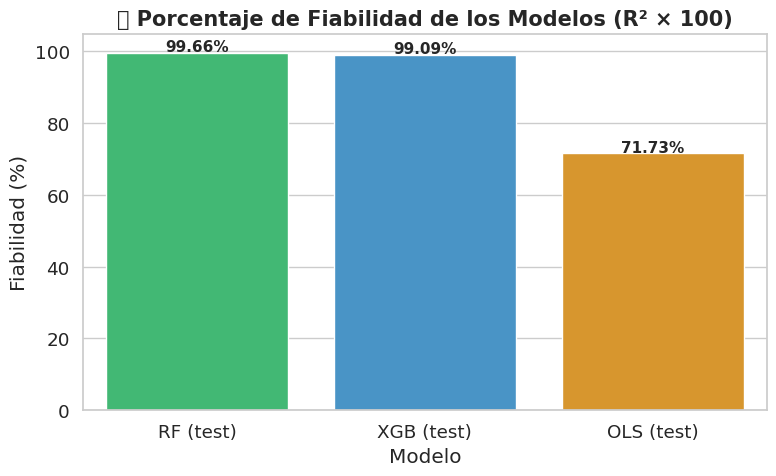

In [3]:
# ===============================================================
# VISUALIZACIÓN: Porcentaje de Fiabilidad (R² × 100)
# ===============================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Crear tabla simplificada
df_fiabilidad = (
    metrics_df[metrics_df["model"].str.contains("test")]
    .copy()
)
df_fiabilidad["Fiabilidad (%)"] = df_fiabilidad["R2"] * 100

# Ordenar por R² descendente
df_fiabilidad = df_fiabilidad.sort_values("R2", ascending=False)

# Estilo gráfico
sns.set(style="whitegrid", font_scale=1.2)

plt.figure(figsize=(8, 5))
bars = sns.barplot(
    data=df_fiabilidad,
    x="model", y="Fiabilidad (%)",
    palette=["#2ecc71", "#3498db", "#f39c12"]
)

# Etiquetas de porcentaje
for i, val in enumerate(df_fiabilidad["Fiabilidad (%)"]):
    plt.text(i, val + 0.3, f"{val:.2f}%", ha="center", fontsize=11, weight="bold")

plt.title("🔍 Porcentaje de Fiabilidad de los Modelos (R² × 100)", fontsize=15, weight="bold")
plt.xlabel("Modelo")
plt.ylabel("Fiabilidad (%)")
plt.ylim(0, 105)
plt.tight_layout()
plt.show()


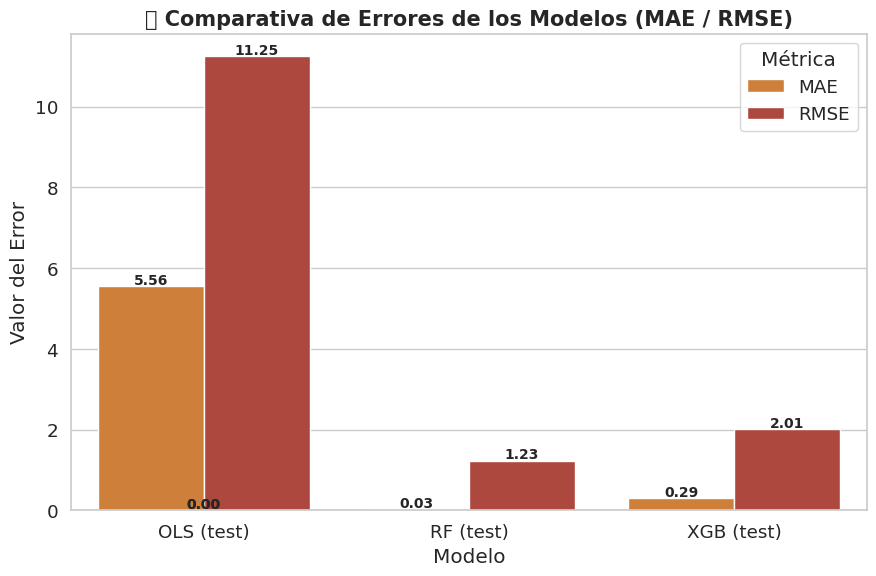

<Figure size 640x480 with 0 Axes>

In [8]:
# ===============================================================
# VISUALIZACIÓN: Comparativa de Errores (MAE / RMSE)
# ===============================================================
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Filtramos las filas de test (rendimiento real)
df_errores = metrics_df[metrics_df["model"].str.contains("test")].copy()

# Reformateamos a formato "long" para que seaborn lo pinte más fácil
df_melted = df_errores.melt(
    id_vars=["model"], 
    value_vars=["MAE", "RMSE"],
    var_name="Métrica", 
    value_name="Error"
)

# Estilo gráfico
sns.set(style="whitegrid", font_scale=1.2)

plt.figure(figsize=(9, 6))
bars = sns.barplot(
    data=df_melted,
    x="model", y="Error", hue="Métrica",
    palette=["#e67e22", "#c0392b"]
)

# Etiquetas con los valores numéricos encima de cada barra
for p in bars.patches:
    height = p.get_height()
    plt.text(
        p.get_x() + p.get_width() / 2, height + 0.05,
        f"{height:.2f}", ha="center", fontsize=10, weight="bold"
    )

plt.title("📉 Comparativa de Errores de los Modelos (MAE / RMSE)", fontsize=15, weight="bold")
plt.xlabel("Modelo")
plt.ylabel("Valor del Error")
plt.legend(title="Métrica")
plt.tight_layout()
plt.show()
plt.savefig(os.path.join(OUT_DIR, "comparativa_errores.png"), dpi=300, bbox_inches="tight")



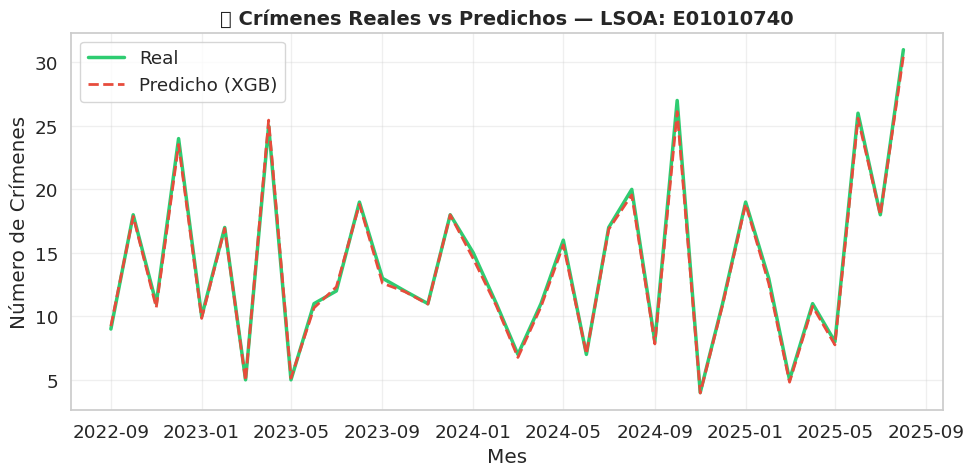

📍 LSOA E01010740 -> MAE: 0.244 | R²: 0.998


In [9]:
# ===============================================================
# VISUALIZACIÓN: Real vs Predicho (Modelo XGBoost)
# ===============================================================
import matplotlib.pyplot as plt
import random

# Seleccionar un LSOA aleatorio o uno específico
lsoa_random = random.choice(df_test["LSOA code"].unique())
# o elige uno manualmente, por ejemplo:
# lsoa_random = "E01000001"

# Filtrar los datos de ese LSOA
df_lsoa = df[df["LSOA code"] == lsoa_random].sort_values("Month")

# Crear matrices DMatrix para predicción
d_lsoa = xgb.DMatrix(df_lsoa[num_cols])
pred_lsoa = xgb_model.predict(d_lsoa)

# Construir DataFrame de comparación
df_plot = pd.DataFrame({
    "Month": df_lsoa["Month"],
    "Real": df_lsoa["crime_count"].values,
    "Predicho (XGB)": pred_lsoa
})

# Gráfico temporal
plt.figure(figsize=(10, 5))
plt.plot(df_plot["Month"], df_plot["Real"], label="Real", color="#2ecc71", linewidth=2.5)
plt.plot(df_plot["Month"], df_plot["Predicho (XGB)"], label="Predicho (XGB)", color="#e74c3c", linestyle="--", linewidth=2)

plt.title(f"📆 Crímenes Reales vs Predichos — LSOA: {lsoa_random}", fontsize=14, weight="bold")
plt.xlabel("Mes")
plt.ylabel("Número de Crímenes")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Métricas locales para el gráfico
mae_local = mean_absolute_error(df_plot["Real"], df_plot["Predicho (XGB)"])
r2_local  = r2_score(df_plot["Real"], df_plot["Predicho (XGB)"])
print(f"📍 LSOA {lsoa_random} -> MAE: {mae_local:.3f} | R²: {r2_local:.3f}")


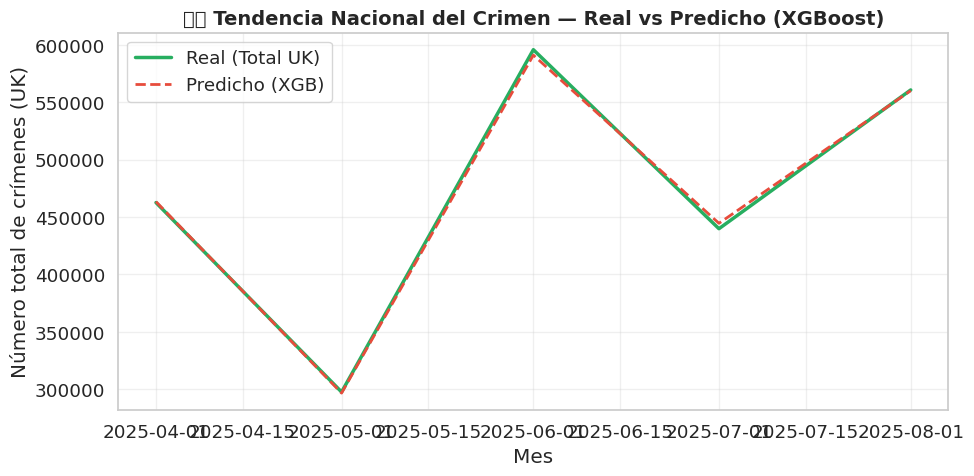

🌍 Tendencia Nacional -> MAE: 2363.794 | R²: 0.999


In [10]:
# ===============================================================
# VISUALIZACIÓN FINAL: Tendencia Nacional — Real vs Predicho
# ===============================================================
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Agregar predicciones y valores reales por mes
# (solo test para medir generalización)
dtest_all = xgb.DMatrix(X_test_imp)
y_pred_test = xgb_model.predict(dtest_all)

df_pred = df_test.copy()
df_pred["Predicho (XGB)"] = y_pred_test

# Sumar crímenes reales y predichos por mes
df_monthly = (
    df_pred.groupby("Month")[["crime_count", "Predicho (XGB)"]]
    .sum()
    .reset_index()
)

# Gráfico temporal
plt.figure(figsize=(10, 5))
plt.plot(df_monthly["Month"], df_monthly["crime_count"], label="Real (Total UK)", color="#27ae60", linewidth=2.5)
plt.plot(df_monthly["Month"], df_monthly["Predicho (XGB)"], label="Predicho (XGB)", color="#e74c3c", linestyle="--", linewidth=2)

plt.title("🇬🇧 Tendencia Nacional del Crimen — Real vs Predicho (XGBoost)", fontsize=14, weight="bold")
plt.xlabel("Mes")
plt.ylabel("Número total de crímenes (UK)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Métricas globales de tendencia
mae_global = mean_absolute_error(df_monthly["crime_count"], df_monthly["Predicho (XGB)"])
r2_global  = r2_score(df_monthly["crime_count"], df_monthly["Predicho (XGB)"])
print(f"🌍 Tendencia Nacional -> MAE: {mae_global:.3f} | R²: {r2_global:.3f}")


In [11]:
df_pred.to_csv(os.path.join(OUT_DIR, "predicciones_xgb_2025.csv"), index=False)


In [12]:
import geopandas as gpd
import folium

# Cargar shapefile LSOA
gdf_lsoa = gpd.read_file("LSOA_2021_UK_Boundaries.shp")

# Fusionar con tus predicciones
gdf_merge = gdf_lsoa.merge(df_pred, on="LSOA code", how="left")

# Crear mapa interactivo
m = folium.Map(location=[54.5, -3], zoom_start=6, tiles="cartodbpositron")
folium.Choropleth(
    geo_data=gdf_merge,
    data=gdf_merge,
    columns=["LSOA code", "Predicho (XGB)"],
    key_on="feature.properties.LSOA21CD",
    fill_color="YlOrRd",
    fill_opacity=0.7,
    line_opacity=0.2,
    legend_name="Predicción de crimen (XGB)"
).add_to(m)

m.save(os.path.join(OUT_DIR, "mapa_hotspots.html"))


ModuleNotFoundError: No module named 'geopandas'